# PathSnap - dataset exploration (EDA)

Partitions analysed: **train** (80 trips) and **student_test** (10 trips). The evaluator partition is not on
disk and is not used. Every table, figure and map below is produced by `eda/run_eda.py` from the raw files;
this notebook only displays them. Each section states the partition it uses.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
sys.path.insert(0, str(ROOT / "eda"))
EDA, DATASET, MAPS = ROOT / "results" / "eda", ROOT / "results" / "dataset", ROOT / "results" / "maps"
pd.set_option("display.width", 200, "display.max_columns", 30)
kn = json.loads((EDA / "key_numbers.json").read_text())
keys = ["trips", "gps_rows", "usable_points", "points_per_trip_min_median_max", "total_hours", "total_km",
        "share_1s_steps", "steps_gt_10s", "steps_gt_60s", "max_gap_s", "steps_gt_70mps", "missing_values_all_files",
        "nodes_median", "arcs_median", "twin_share_mean", "largest_scc_share_median", "route_broken_links",
        "trips_with_broken_links", "share_points_gt_50m"]
pd.DataFrame({p: {k: kn["partitions"][p][k] for k in keys} for p in kn["partitions"]})

,train,student_test
trips,80,10
gps_rows,208417,19160
usable_points,208417,19160
points_per_trip_min_median_max,"[361, 1529, 19313]","[262, 1420, 3958]"
total_hours,126.231211,5.625
total_km,2981.283149,297.487492
share_1s_steps,0.965037,0.986214
steps_gt_10s,590,27
steps_gt_60s,69,1
max_gap_s,153064.0,210.0


## 1. Inventory (train + student_test)
File presence, sizes and row counts; inferred column types.

,partition,trips,track_files,nodes_files,arcs_files,route_files,gps_observations,nodes,arcs,route_arcs,total_mb
0,student_test,10,10,10,10,10,19160,90689,185041,3477,4.368591
1,train,80,80,80,80,80,208417,1933485,3876904,31336,89.737452


,file,column,dtype,trips
0,.arcs,from_node,int64,90
1,.arcs,to_node,int64,90
2,.nodes,lat,float64,90
3,.nodes,lon,float64,90
4,.route,arc_id,int64,90
5,.track,lat,float64,90
6,.track,lon,float64,90
7,.track,t,float64,90


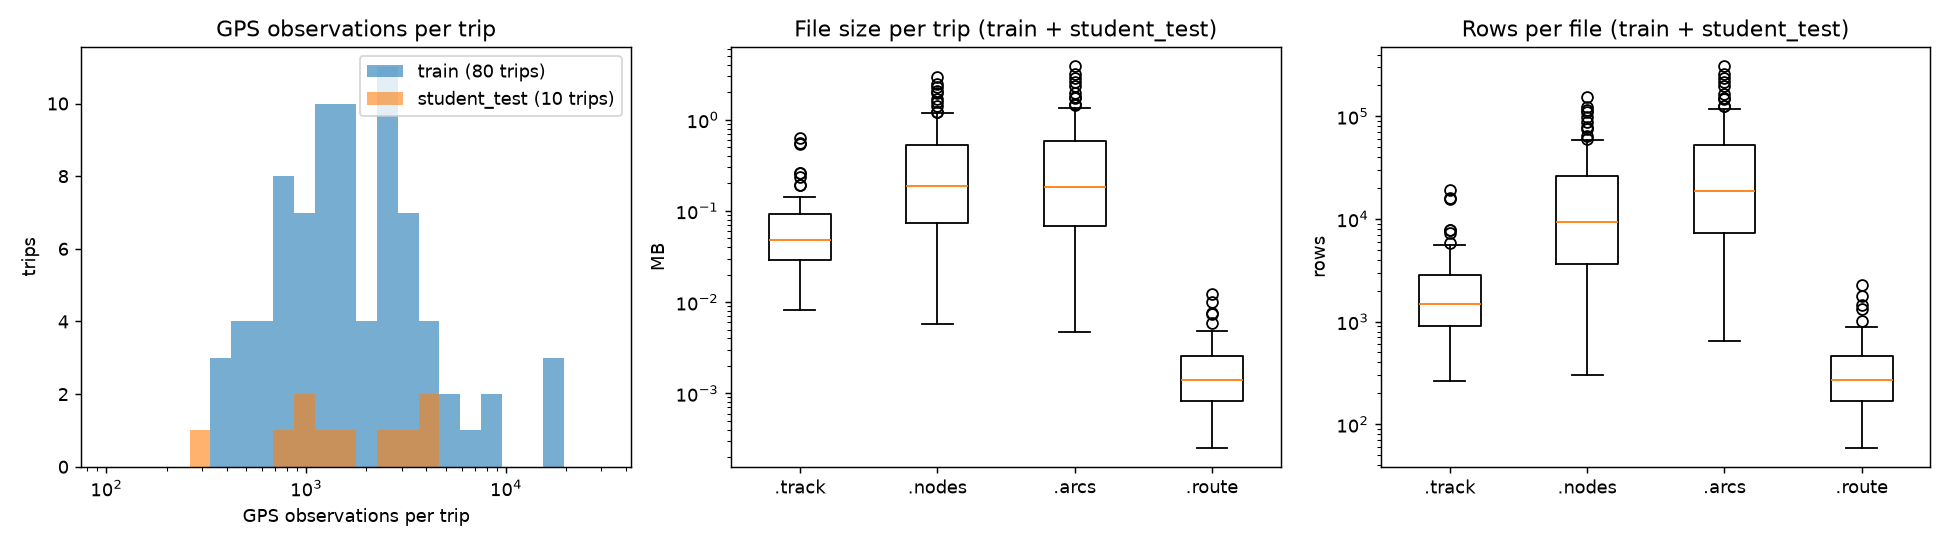

In [2]:
display(pd.read_csv(EDA / "inventory_by_partition.csv"))
display(pd.read_csv(EDA / "dtypes.csv"))
Image(EDA / "fig01_inventory.png")

## 2. Missing and invalid values (train + student_test)

,partition,track_missing_values,nodes_missing_values,arcs_missing_values,route_missing_values,gps_nonfinite_rows,gps_out_of_range_rows,gps_null_island_rows,t_duplicate_steps,t_backward_steps,t_non_integer,dup_consecutive_fixes,dropped_points
0,student_test,0,0,0,0,0,0,0,0,0,0,0,0
1,train,0,0,0,0,0,0,0,0,0,9659,6,0


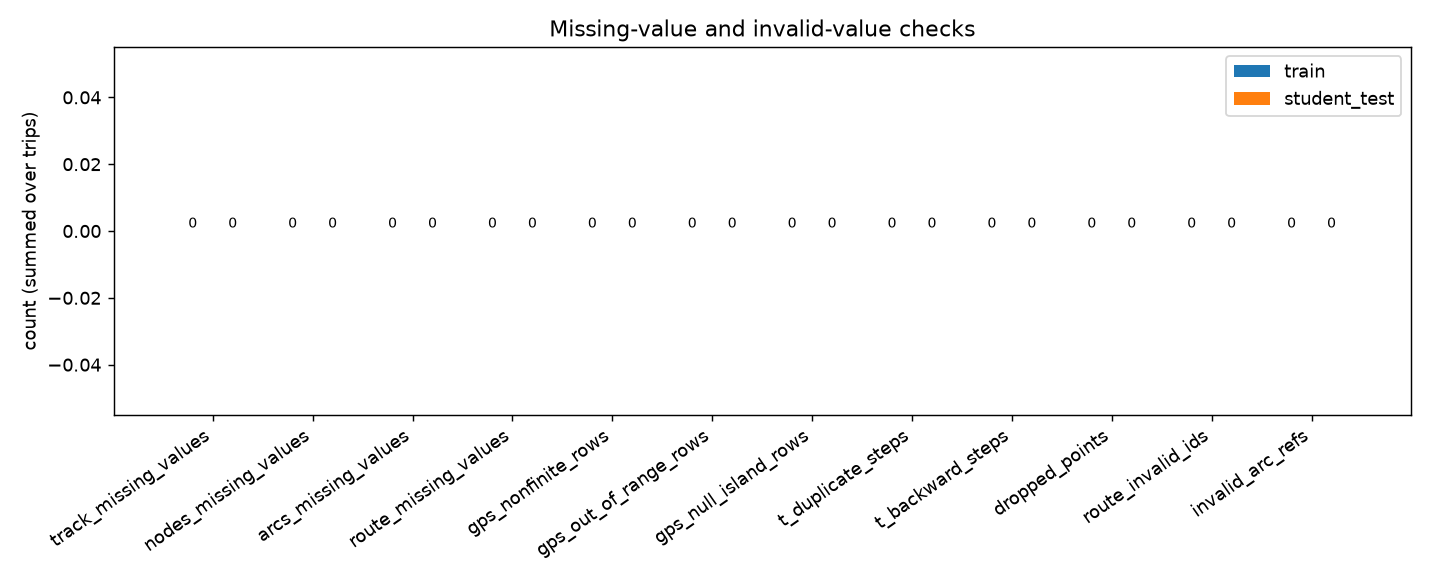

In [3]:
display(pd.read_csv(EDA / "missing_values.csv"))
Image(EDA / "fig02_missing_values.png")

## 3. Timestamp ordering and sampling gaps (train + student_test)

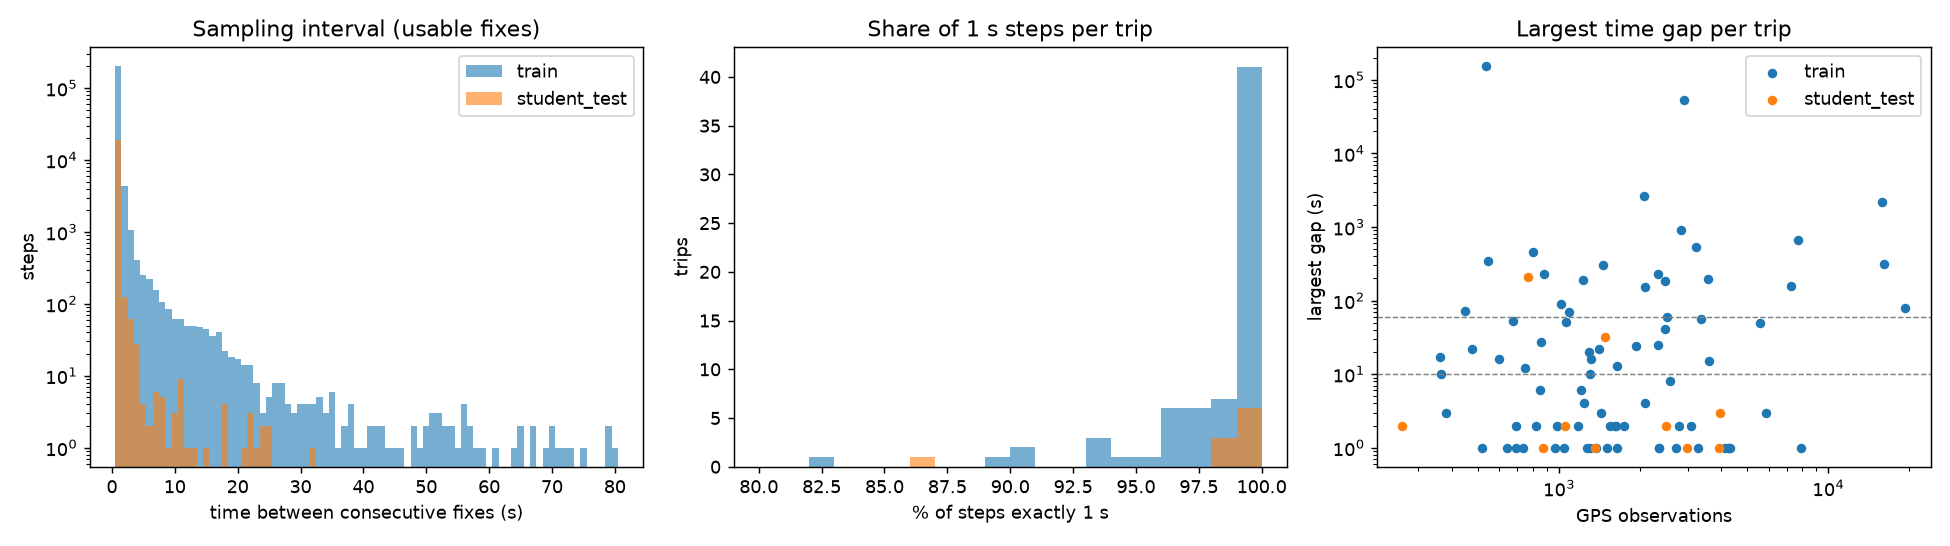

In [4]:
Image(EDA / "fig03_sampling_intervals.png")

In [5]:
s = pd.read_csv(EDA / "trip_stats.csv", dtype={"trip_id": str})
s.loc[s["gaps_gt_60s"] > 0, ["partition", "trip_id", "usable_points", "share_1s_steps", "max_gap_s",
                             "gaps_gt_10s", "gaps_gt_60s", "max_step_m"]].sort_values("max_gap_s", ascending=False)

,partition,trip_id,usable_points,share_1s_steps,max_gap_s,gaps_gt_10s,gaps_gt_60s,max_step_m
72,train,00000090,536,0.581308,153064.0,6,1,35.727563
61,train,00000078,2909,0.755158,52810.0,25,1,215.685775
55,train,00000069,2067,0.989351,2658.0,2,2,66.338377
16,train,00000021,15783,0.999620,2161.0,2,2,45.860559
8,train,00000011,2828,0.999646,909.0,1,1,50.394711
34,train,00000042,7739,0.989532,670.0,37,17,58.226827
64,train,00000081,3224,0.719826,536.0,86,15,109.403969
18,train,00000024,801,0.971250,458.0,2,2,65.753130
36,train,00000044,546,0.900917,341.0,2,1,36.216846
67,train,00000084,16031,0.996881,312.0,4,2,49.098515


## 4. Speeds between consecutive fixes (train + student_test)

,partition,trip_id,median_speed_mps,p95_speed_mps,max_speed_mps,steps_gt_70mps
0,train,00000001,41.365140,58.754875,72.416298,1
6,train,00000008,7.601373,15.765222,70.031398,1
10,train,00000013,28.486633,46.289128,141.838400,95
25,train,00000032,41.037335,65.958057,83.416343,43
26,train,00000033,6.906444,16.957071,142.115214,1
35,train,00000043,29.036799,43.866220,131.731675,2
43,train,00000053,22.666493,39.293179,71.243013,1
46,train,00000057,13.480660,27.580556,83.406542,1
62,train,00000079,15.884361,28.983308,180.540474,2
73,train,00000092,13.260428,26.429530,85.231634,3


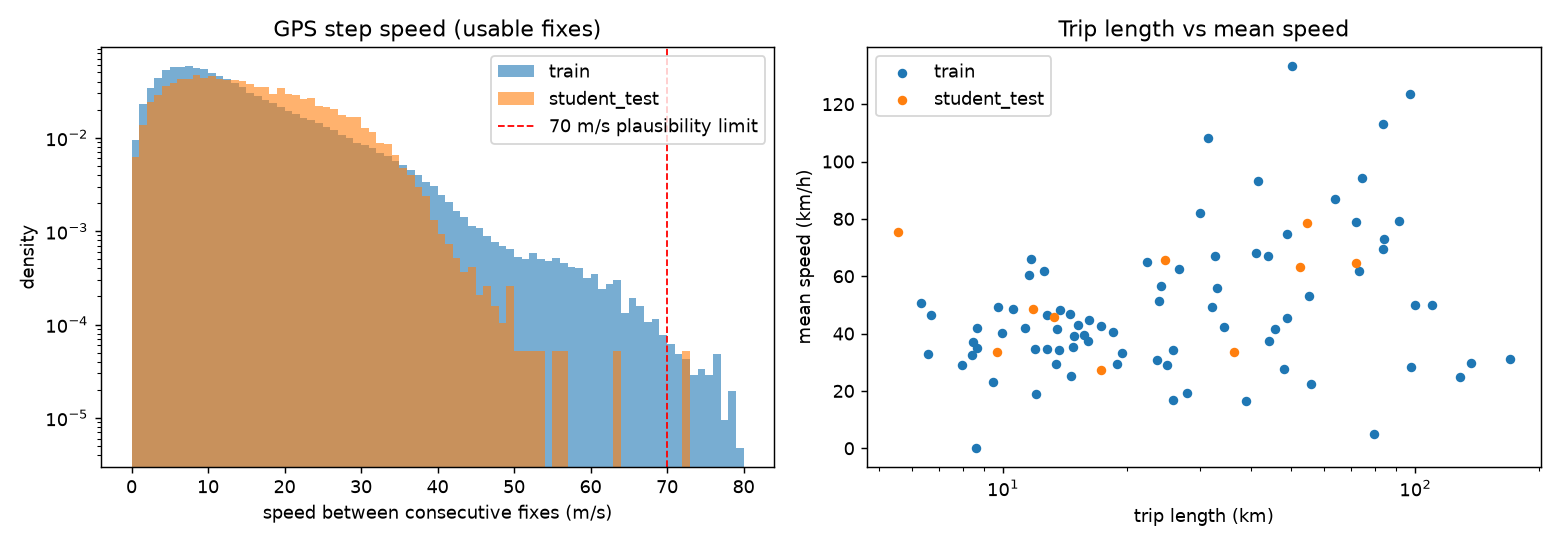

In [6]:
display(s.loc[s["steps_gt_70mps"] > 0, ["partition", "trip_id", "median_speed_mps", "p95_speed_mps",
                                        "max_speed_mps", "steps_gt_70mps"]])
Image(EDA / "fig04_speed.png")

## 5. Geographic extent and GPS coordinate distributions (train + student_test)

UTM zones used: 25 | southern-hemisphere trips: ['00000071', '00000080', '00000098']


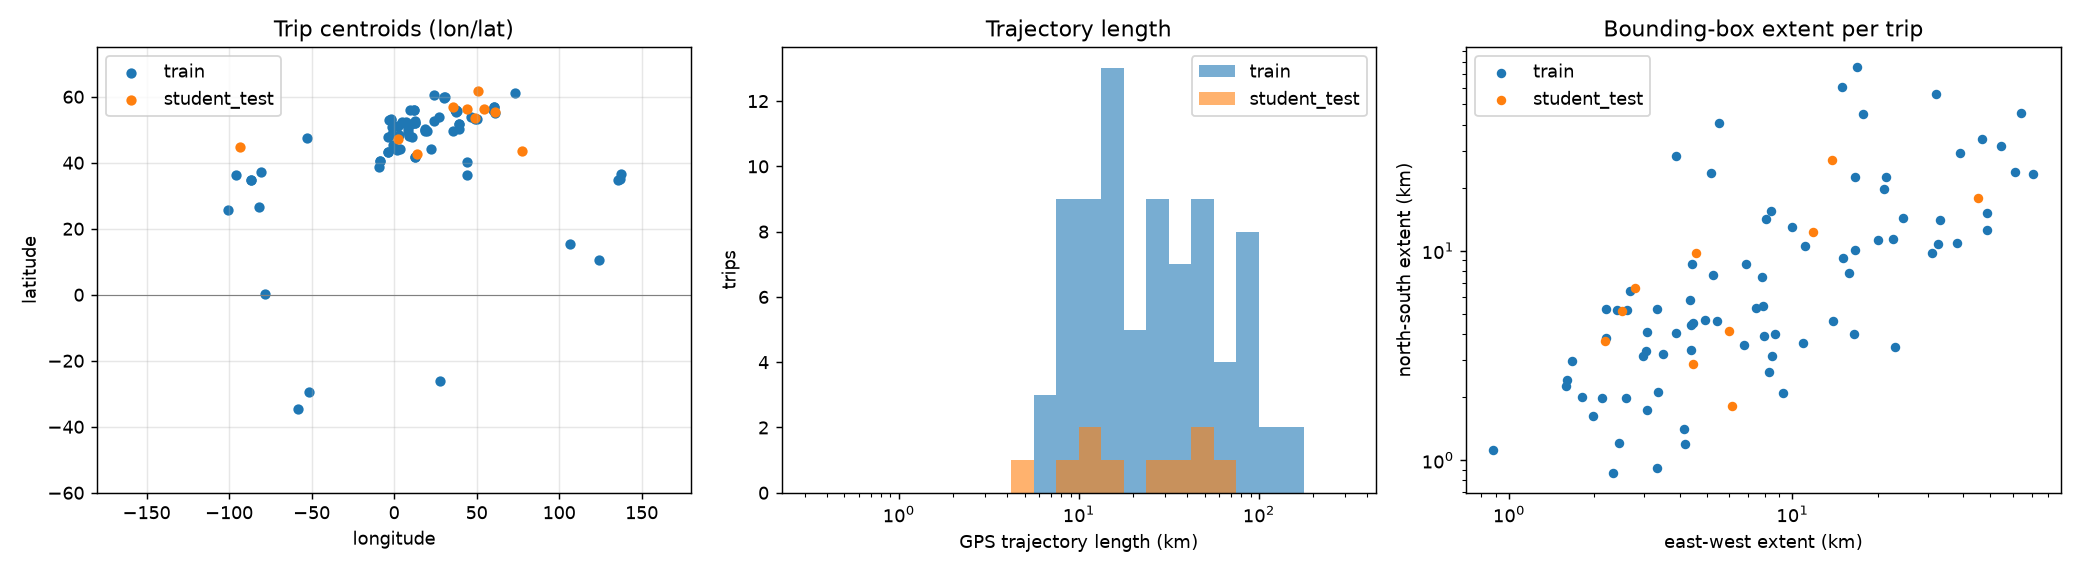

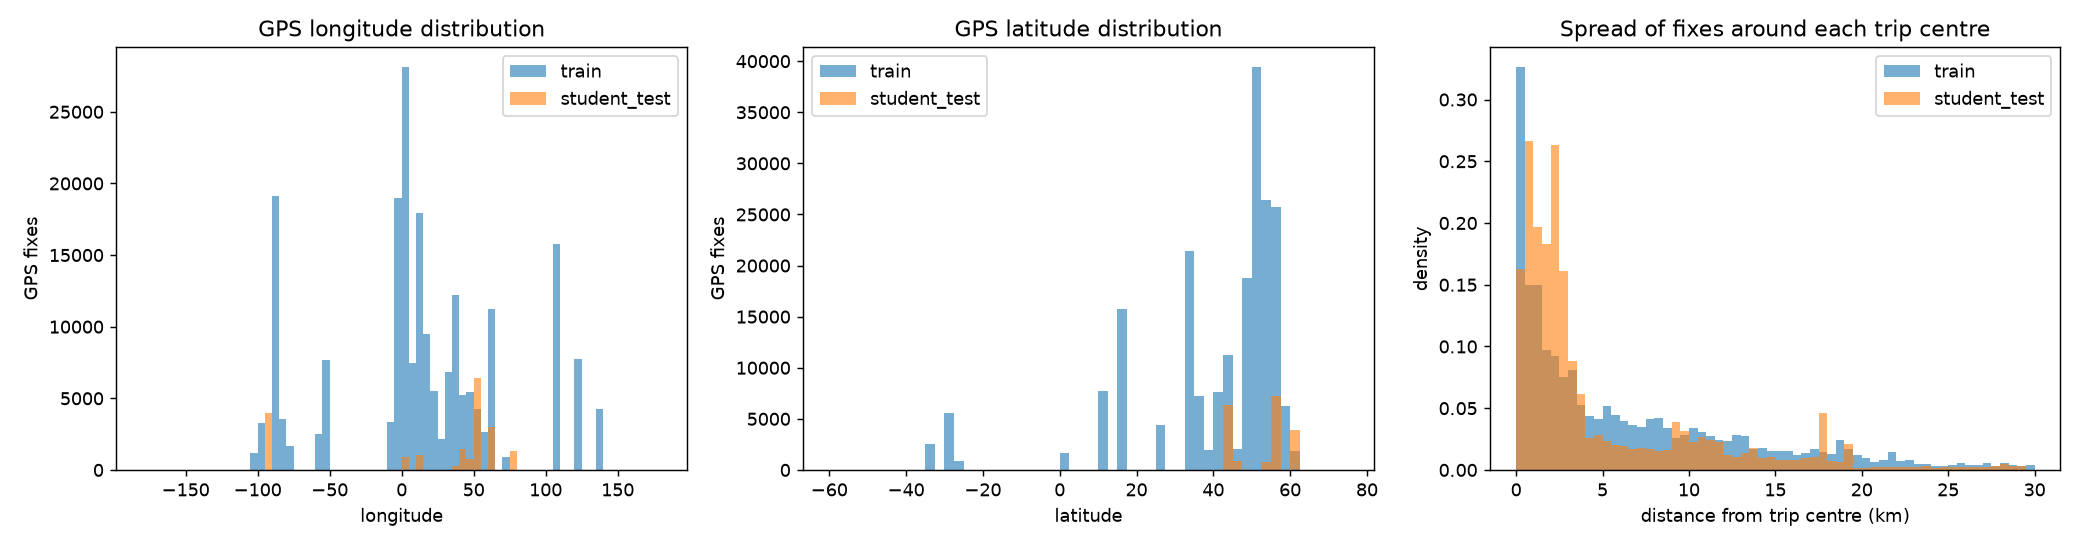

In [7]:
print("UTM zones used:", kn["utm_zones"], "| southern-hemisphere trips:", kn["southern_hemisphere_trips"])
display(Image(EDA / "fig05_geographic_extent.png"))
Image(EDA / "fig06_coordinate_distributions.png")

## 6. Trajectory patterns (12 train trips, projected metres)

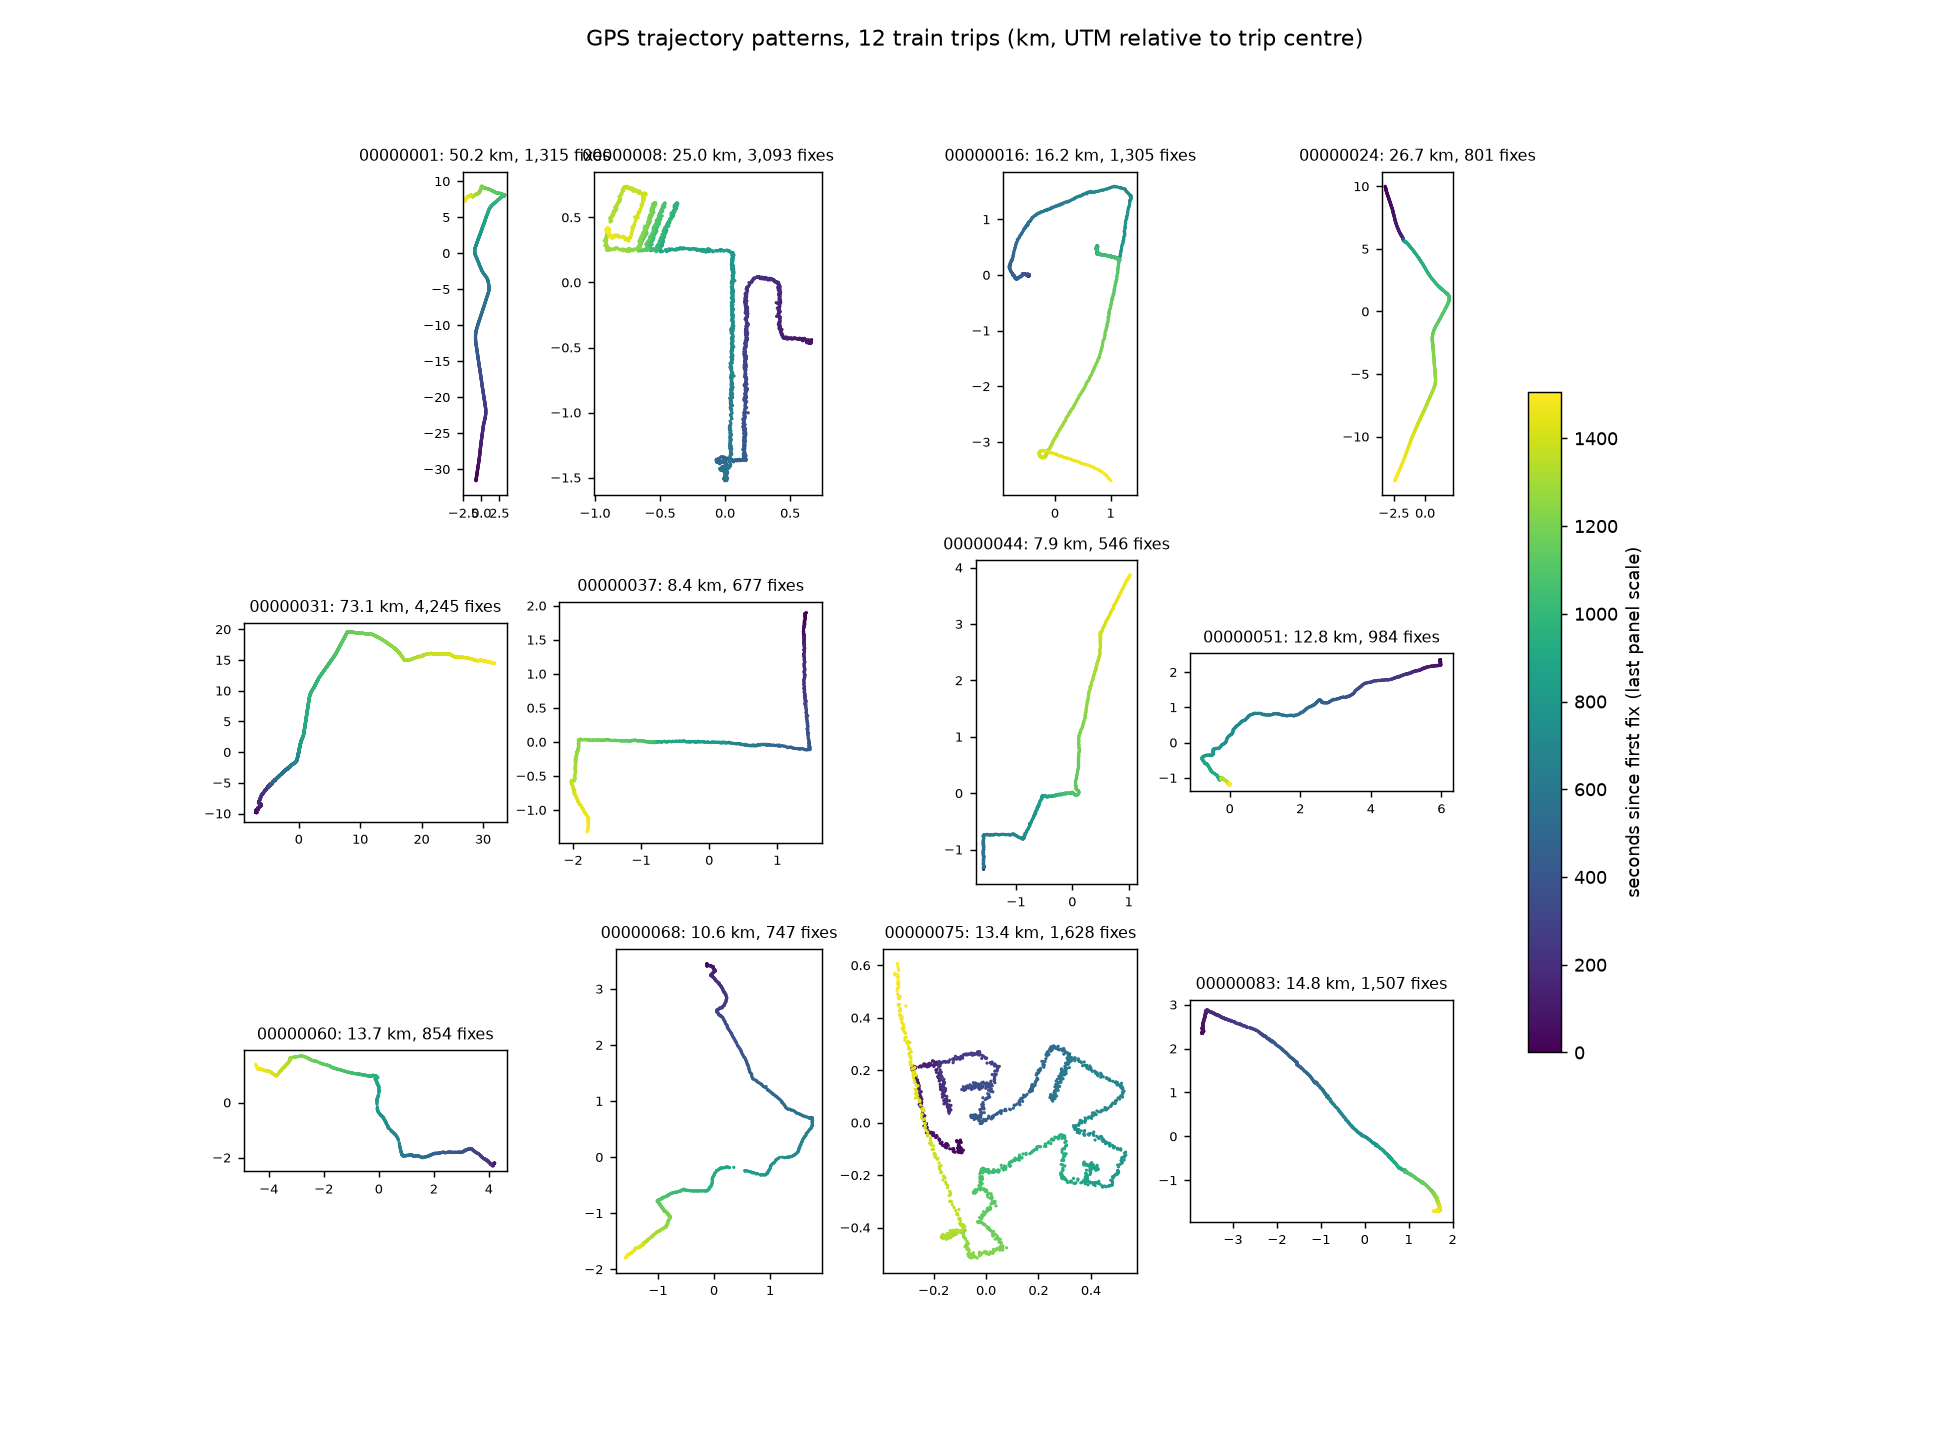

In [8]:
Image(EDA / "fig07_trajectory_patterns.png")

## 7. Road-network size and connectivity (train + student_test)

partition                  student_test      train
nodes               count        10.000     80.000
                    mean       9068.900  24168.562
                    std        7452.176  32272.296
                    min        1770.000    299.000
                    25%        4908.000   3487.750
...                                 ...        ...
arc_length_median_m min          15.845      6.751
                    25%          20.242     21.484
                    50%          31.946     24.578
                    75%          40.123     35.113
                    max          53.337     85.138

[80 rows x 2 columns]

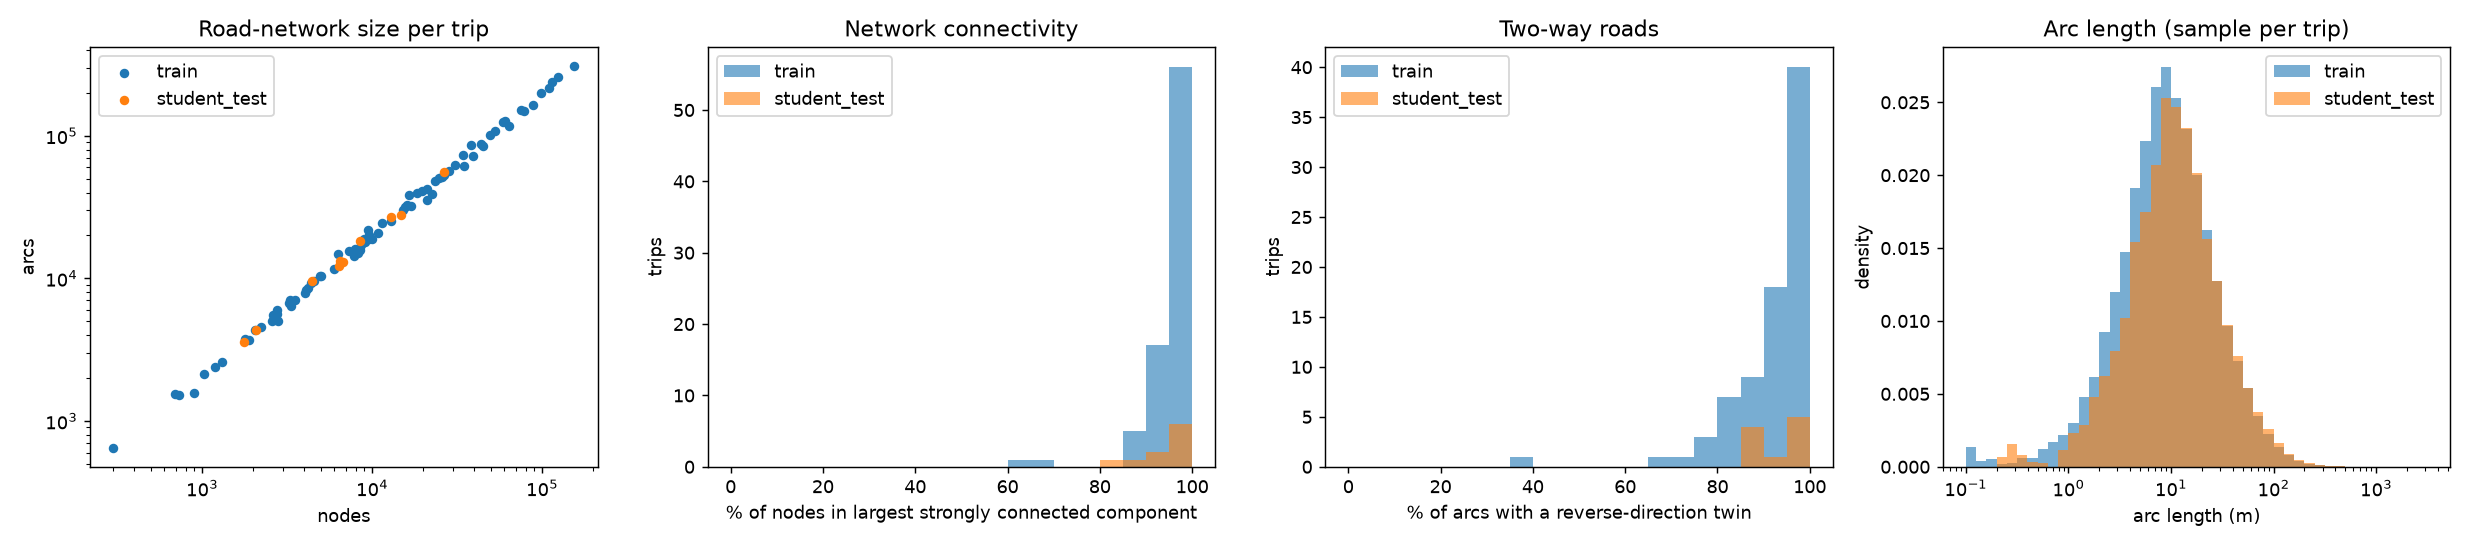

In [9]:
net = pd.read_csv(EDA / "network_stats.csv", dtype={"trip_id": str})
display(net.groupby("partition")[["nodes", "arcs", "twin_share", "isolated_nodes", "strong_components",
                                  "largest_scc_share", "zero_length_arcs", "self_loops", "duplicate_arcs",
                                  "arc_length_median_m"]].describe().T.round(3))
Image(EDA / "fig08_road_network.png")

## 8. Reference routes (train + student_test)

partition                         student_test         train
route_arcs                sum      3477.000000  31336.000000
                          median    250.000000    280.000000
                          min        95.000000     59.000000
                          max      1323.000000   2266.000000
route_km                  sum       248.059627   2228.524410
                          median     14.763187     14.313773
                          min         5.292246      5.014350
                          max        64.813501     94.338958
route_broken_links        sum         1.000000     13.000000
                          median      0.000000      0.000000
                          min         0.000000      0.000000
                          max         1.000000      3.000000
route_repeated_arcs       sum       255.000000     67.000000
                          median      0.000000      0.000000
                          min         0.000000      0.000000
                          max       255.000000     29.000000
route_uturns              sum         8.000000     46.000000
                          median      0.000000      0.000000
                          min         0.000000      0.000000
                          max         3.000000      9.000000
route_arcs_in_largest_scc sum         9.998488     79.083373
                          median      1.000000      1.000000
                          min         0.998488      0.457143
                          max         1.000000      1.000000

,partition,trip_id,route_pos,arc_from,arc_to,straight_gap_m,network_bridge_m,arc_to_is_twin
0,train,00000002,53,1848,10863,324.625997,1056.950640,False
1,train,00000019,94,85589,51027,241.622889,364.341444,False
2,train,00000019,151,55059,55050,255.450958,512.845403,False
3,train,00000019,300,953,23709,597.621129,600.328042,False
4,train,00000033,164,1003,1002,91.959177,91.959177,False
5,train,00000041,12,1264,519,57.350269,402.421230,False
6,train,00000042,1212,14661,17989,30.658043,30.658043,False
7,train,00000069,153,10165,10172,40.969034,62.387333,False
8,train,00000075,31,507,509,10.643252,925.264580,False
9,train,00000075,62,134,552,73.144945,1211.533477,False


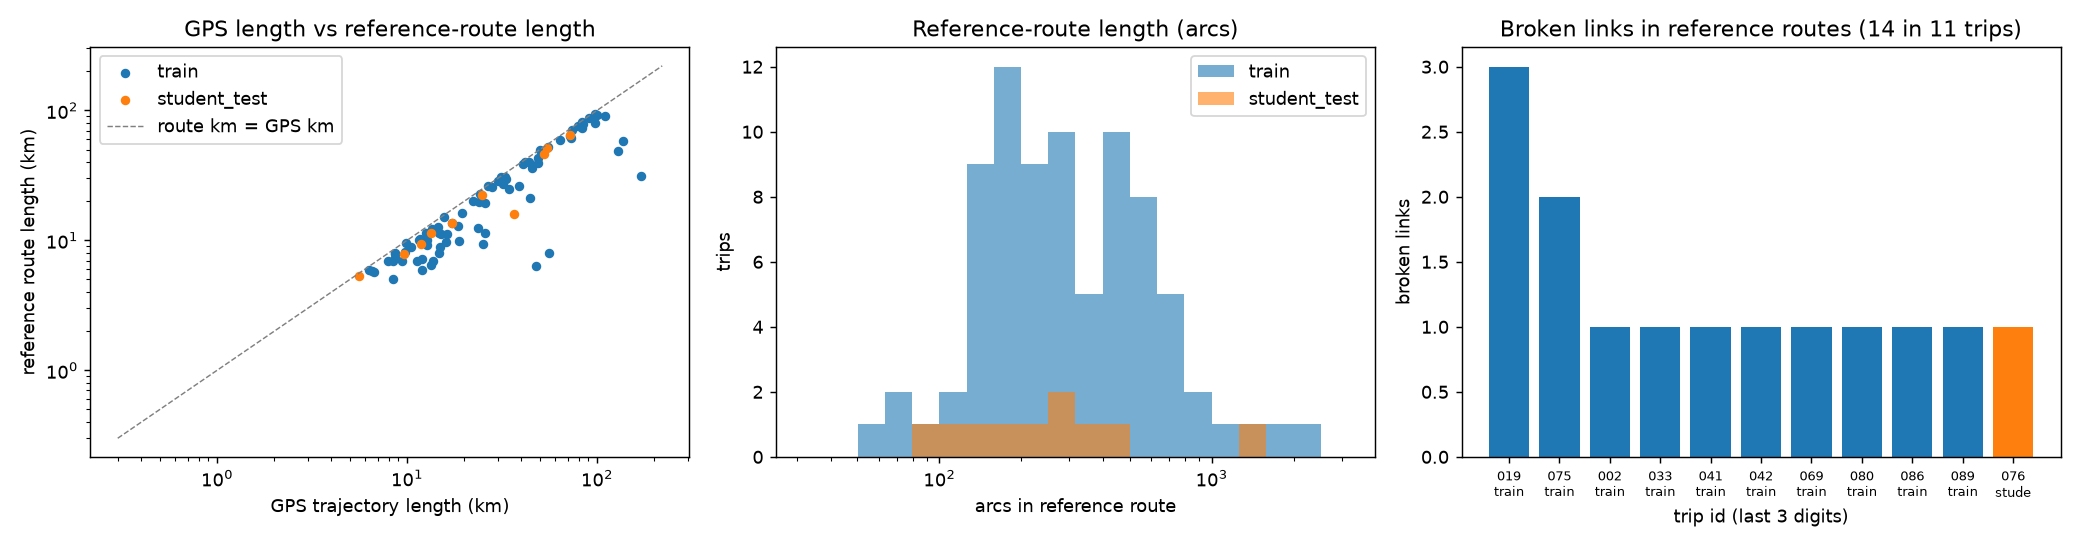

In [10]:
r = pd.read_csv(EDA / "route_stats.csv", dtype={"trip_id": str})
display(r.groupby("partition")[["route_arcs", "route_km", "route_broken_links", "route_repeated_arcs",
                                "route_uturns", "route_arcs_in_largest_scc"]].agg(["sum", "median", "min", "max"]).T)
display(pd.read_csv(EDA / "broken_links.csv", dtype={"trip_id": str}))
Image(EDA / "fig09_reference_routes.png")

## 9. GPS noise relative to the reference route (train + student_test)
Distance from each fix to its aligned reference arc (monotone alignment, `pathsnap.labels`, no cut-off).
The candidate radius / K grid was computed on **train** only by `scripts/candidate_params.py`.

,train,student_test
p50,5.7,5.3
p75,10.9,9.0
p90,89.8,13.5
p95,142.4,16.9
p99,208.7,28.2


,partition,trip_id,share_points_gt_50m,longest_far_run_points,label_dist_median_m
44,train,00000054,0.888987,15584,140.189280
26,train,00000033,0.590178,3042,122.413242
1,train,00000002,0.119840,552,5.775519
53,train,00000066,0.090173,203,6.590082
35,train,00000043,0.071921,89,11.011641
64,train,00000081,0.044355,129,4.536955
76,train,00000096,0.044329,145,4.453868
67,train,00000084,0.036991,255,6.572137


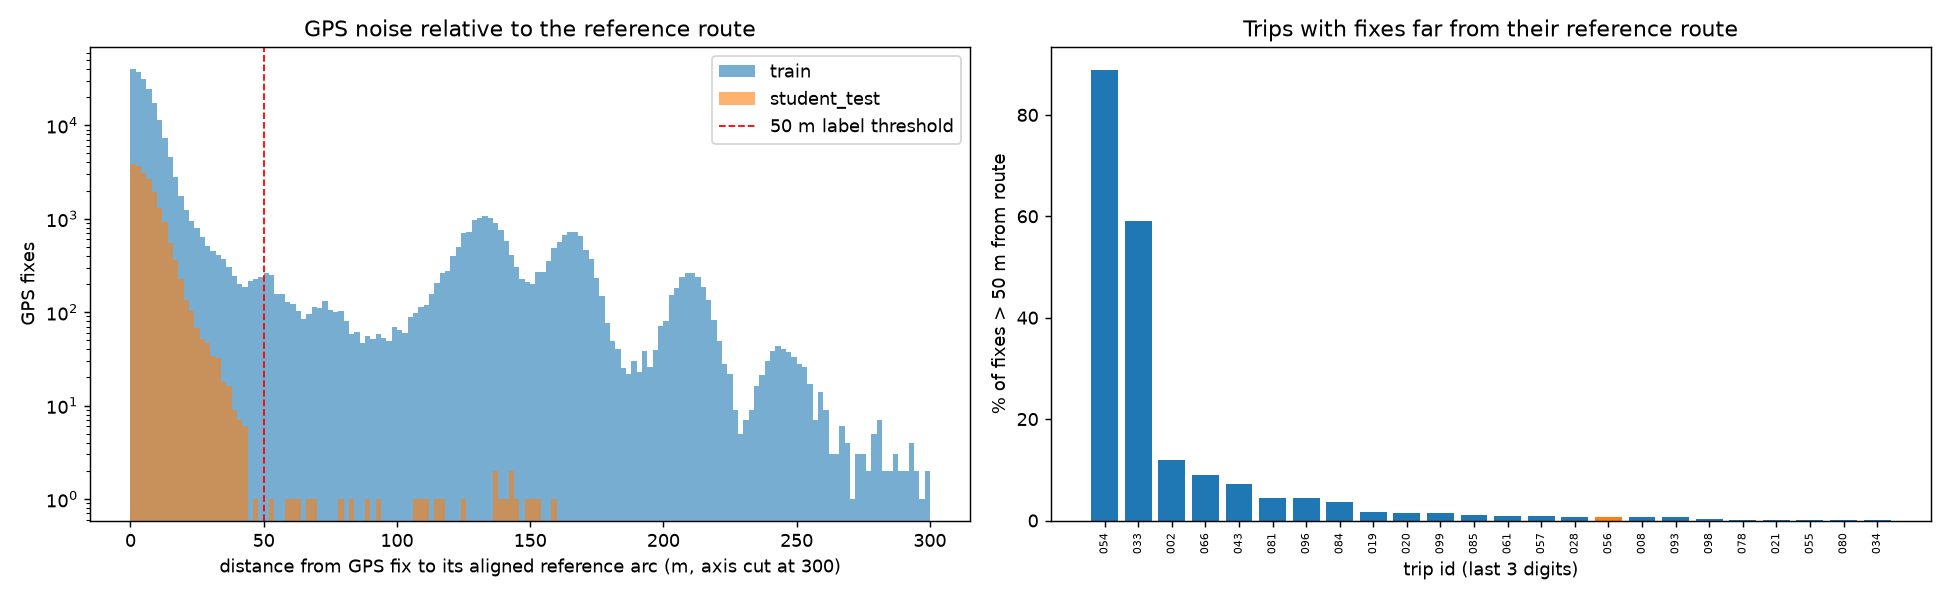

radius_m,10,15,20,25,30,40,50,75,100,150
k,,,,,,,,,,
2,22.65,12.91,10.34,9.42,8.89,8.27,8.11,8.11,8.11,8.11
4,19.64,8.69,5.59,4.45,3.84,3.11,2.90,2.90,2.90,2.90
6,19.05,7.69,4.37,3.10,2.41,1.63,1.40,1.40,1.40,1.40
8,18.93,7.47,4.05,2.73,1.99,1.15,0.91,0.91,0.91,0.91
10,18.89,7.39,3.94,2.58,1.82,0.96,0.71,0.71,0.71,0.71
12,18.87,7.35,3.88,2.49,1.72,0.85,0.59,0.59,0.59,0.59
16,18.84,7.32,3.83,2.43,1.62,0.74,0.47,0.47,0.47,0.47
20,18.82,7.28,3.79,2.38,1.57,0.64,0.28,0.28,0.28,0.28
24,18.82,7.26,3.76,2.36,1.55,0.60,0.17,0.17,0.17,0.17


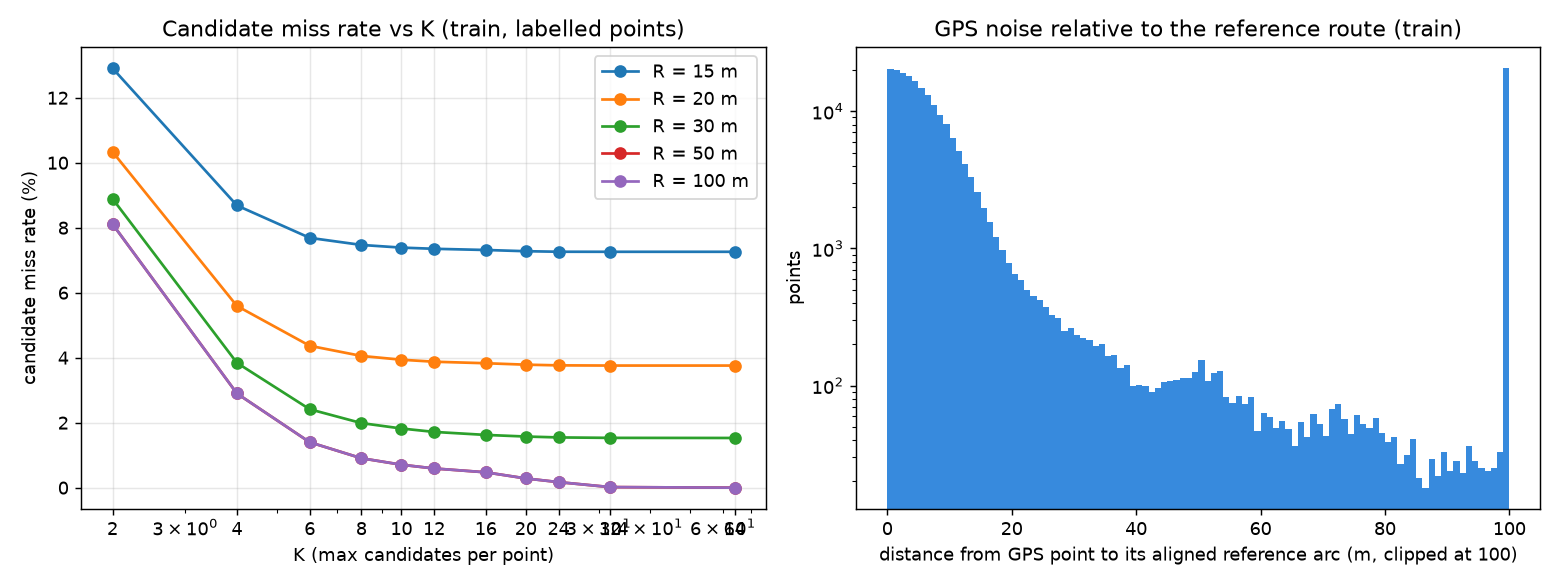

In [11]:
display(pd.DataFrame({p: kn["partitions"][p]["label_dist_percentiles_m"] for p in kn["partitions"]}).round(1))
display(r.sort_values("share_points_gt_50m", ascending=False).head(8)[
    ["partition", "trip_id", "share_points_gt_50m", "longest_far_run_points", "label_dist_median_m"]])
display(Image(EDA / "fig10_gps_vs_route_distance.png"))
g = pd.read_csv(DATASET / "candidate_grid.csv")
display((100 * g.pivot(index="k", columns="radius_m", values="miss_rate")).round(2))
Image(DATASET / "candidate_miss_rate.png")

## 10. Representative trips (train, projected metres)

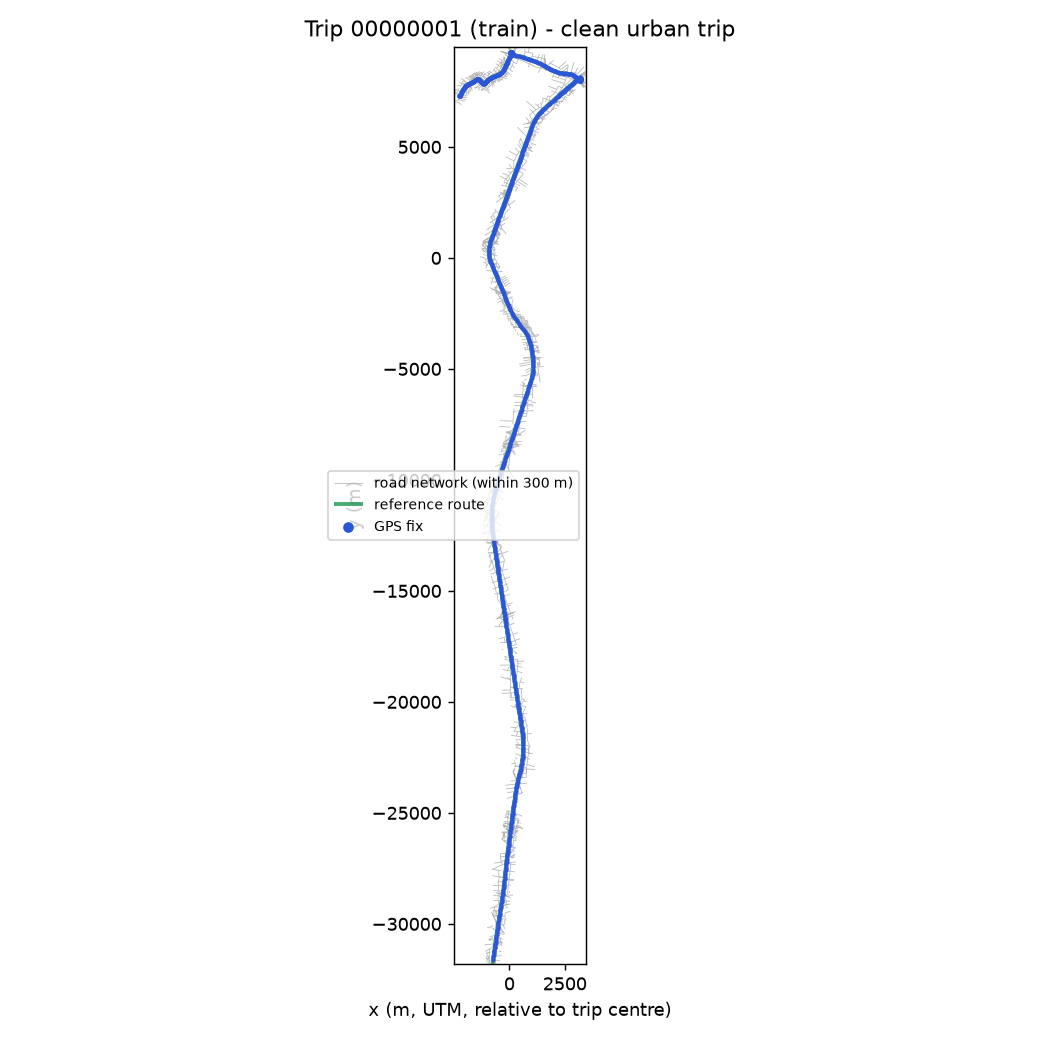

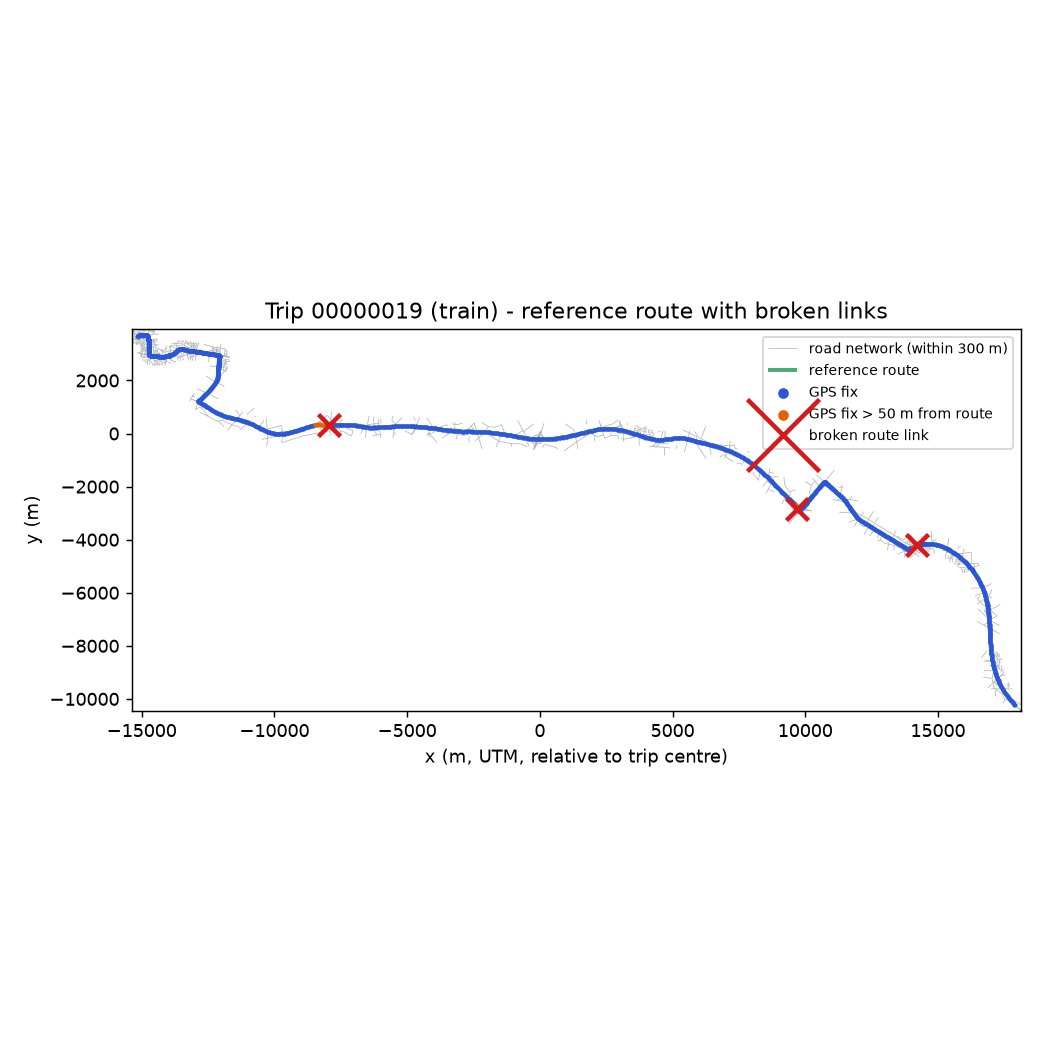

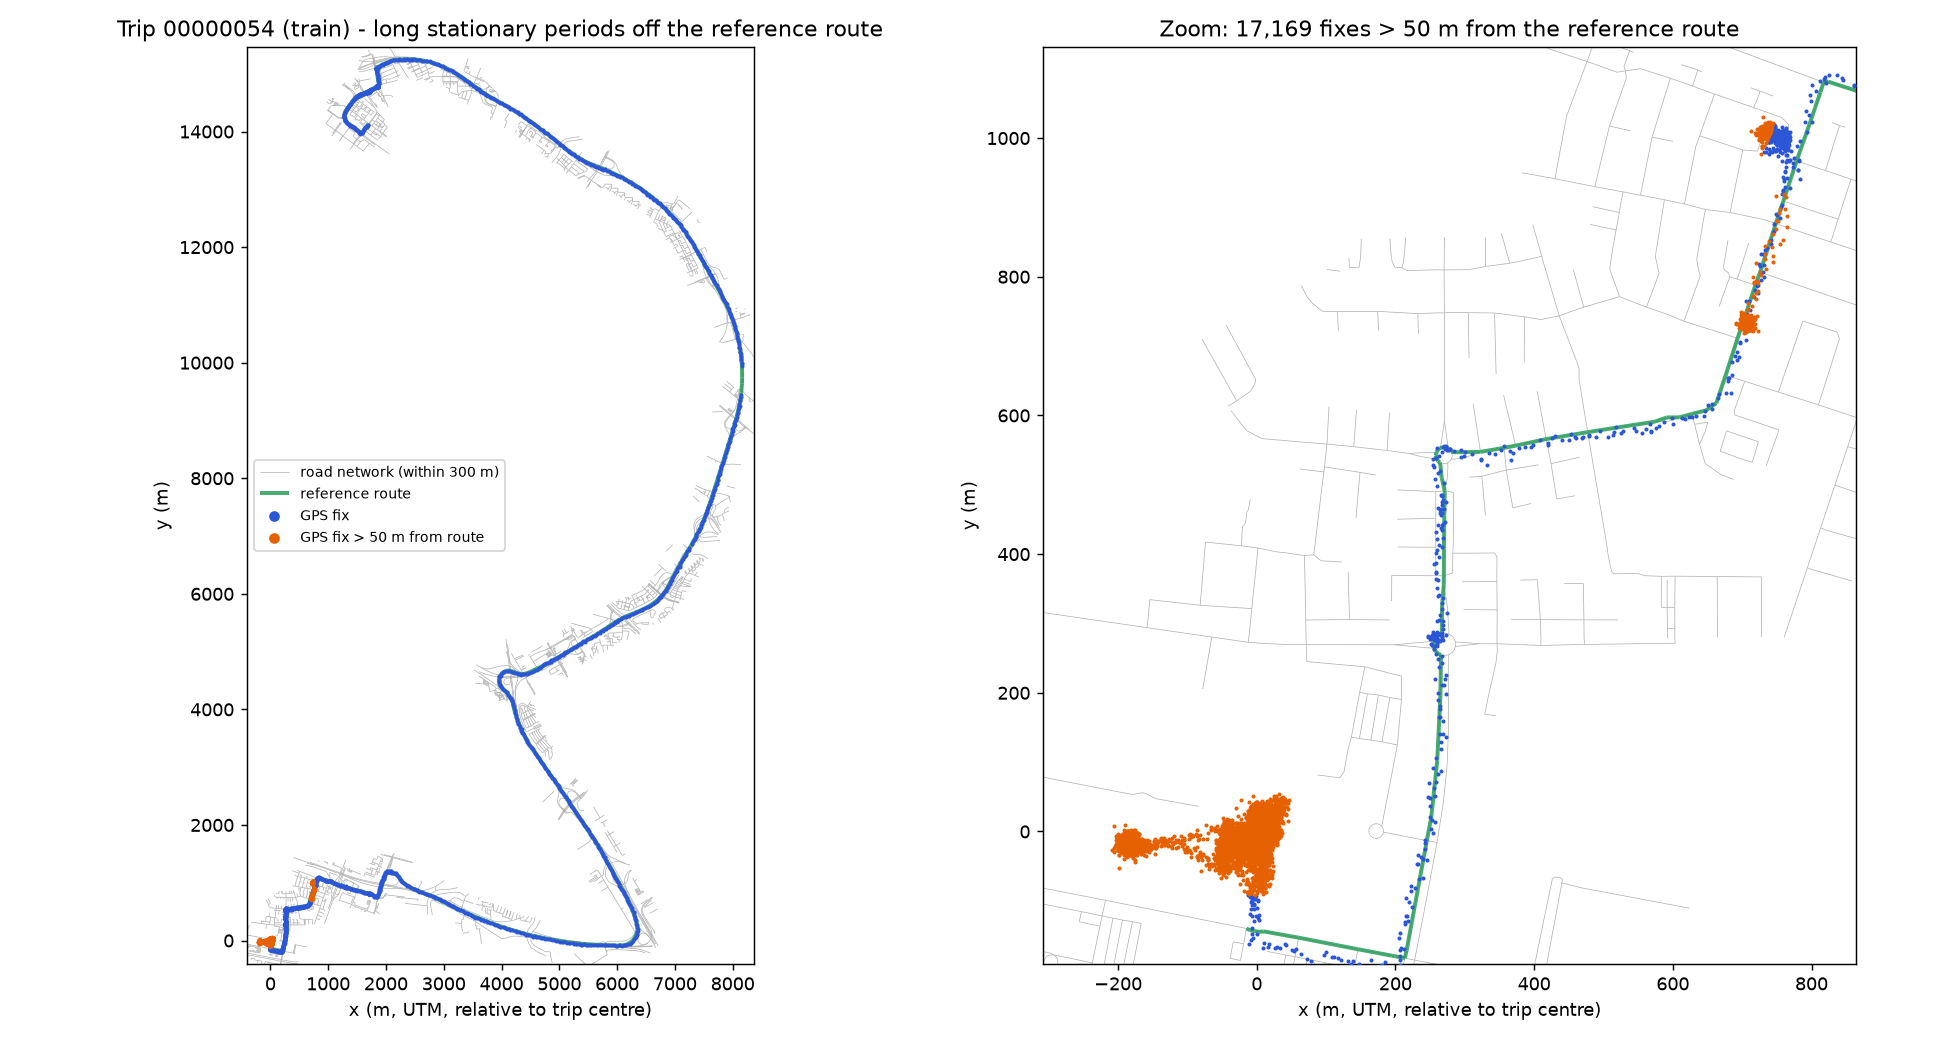

In [12]:
for tid in ["00000001", "00000019", "00000054"]:
    display(Image(EDA / f"trip_{tid}_projected.png"))

## 11. Interactive Folium map - trip 00000001 (train)
GPS fixes, road network within 300 m and the reference route, with layer control. The other maps are in
`results/maps/` (`eda_world_overview.html`, `eda_trip_00000019.html`, `eda_trip_00000054.html`).

In [13]:
from pathsnap import config
import run_eda
run_eda.trip_map(config.PARTITIONS["train"] / "00000001", "clean urban trip")

## 12. Data-quality log (train + student_test)

In [14]:
Markdown((EDA / "data_quality.md").read_text(encoding="utf-8"))

# PathSnap data-quality log

Generated by `eda/run_eda.py` from the raw files. Partitions: **train** (80 trips) and **student_test** (10 trips). The evaluator partition is not on disk and was not used. Numbers below are measured, not assumed.

## Files and types (train + student_test)
- All four files (`.track`, `.nodes`, `.arcs`, `.route`) are present in 90/90 trips.
- Column counts: .track [3], .nodes [2], .arcs [2], .route [1] (matches the documented layout).
- Inferred dtypes (pandas, no forced dtype): .arcs.from_node: int64; .arcs.to_node: int64; .nodes.lat: float64; .nodes.lon: float64; .route.arc_id: int64; .track.lat: float64; .track.lon: float64; .track.t: float64.
- Track timestamps are relative seconds (first fix at t = 1-693 s), not epoch times; 9659 timestamps are non-integer.

## Missing and invalid values
- Missing values over all files: train 0, student_test 0.
- GPS rows non-finite / out of range / (0,0): 0 / 0 / 0.
- Duplicate timestamps: 0; backward timestamps: 0. Rows dropped by `clean_track`: train 0, student_test 0.
- Repeated consecutive fixes (same lon/lat, later timestamp - vehicle standing still): 6 steps. **Decision:** kept (negligible; the heading feature is neutralised anyway when the vehicle barely moves).
- Route arc ids outside the network: 0; arcs referencing missing nodes: 0.

## Sampling and gaps
- Share of exactly-1 s steps: train 96.50 %, student_test 98.62 %.
- Steps > 10 s: train 590 (in 40 trips), student_test 27 (in 2 trips).
- Steps > 60 s: train 69 (in 22 trips), student_test 1 (in 1 trips). Largest gap: train 153064 s, student_test 210 s.
- Trips with any gap > 60 s: 00000002 (train, max 160 s), 00000006 (train, max 301 s), 00000011 (train, max 909 s), 00000014 (train, max 72 s), 00000021 (train, max 2161 s), 00000024 (train, max 458 s), 00000028 (train, max 196 s), 00000041 (train, max 89 s), 00000042 (train, max 670 s), 00000043 (train, max 230 s), 00000044 (train, max 341 s), 00000054 (train, max 79 s), 00000055 (train, max 184 s), 00000069 (train, max 2658 s), 00000070 (train, max 152 s), 00000078 (train, max 52810 s), 00000081 (train, max 536 s), 00000084 (train, max 312 s), 00000085 (train, max 70 s), 00000088 (train, max 232 s), 00000089 (train, max 193 s), 00000090 (train, max 153064 s), 00000065 (student_test, max 210 s).
- Steps faster than 70 m/s: train 150, student_test 1 (trips: 00000001 (1), 00000008 (1), 00000013 (95), 00000032 (43), 00000033 (1), 00000043 (2), 00000053 (1), 00000057 (1), 00000079 (2), 00000092 (3), 00000040 (1)).

## Geography and projection
- Trips fall in 25 different UTM zones; southern-hemisphere trips: 00000071, 00000080, 00000098.
- **Decision:** each trip is projected into the UTM zone of its median GPS fix (`pathsnap.geo.Projector`); distances/angles are computed in metres in that frame. Degrees are never used as distances.

## Road network
- Size: nodes median 9,608 (max 155,003), arcs median 19,526 (max 307,392) on train.
- Arcs with a reverse-direction twin (two-way roads): mean 92.2 % (train), 92.7 % (student_test). Twins share geometry, so direction must come from heading.
- Largest strongly connected component: median 96.4 % of nodes (min 63.6 %). Isolated nodes: 0. Zero-length arcs: 106; self-loops: 24; duplicate arcs: 1903.

## Reference routes
- Broken links (arc i end != arc i+1 start): train 13 in 10 trips, student_test 1 in 1 trips (details in `broken_links.csv`).
  - 00000002 (train) position 53: straight gap 325 m, network bridge 1057 m
  - 00000019 (train) position 94: straight gap 242 m, network bridge 364 m
  - 00000019 (train) position 151: straight gap 255 m, network bridge 513 m
  - 00000019 (train) position 300: straight gap 598 m, network bridge 600 m
  - 00000033 (train) position 164: straight gap 92 m, network bridge 92 m
  - 00000041 (train) position 12: straight gap 57 m, network bridge 402 m
  - 00000042 (train) position 1212: straight gap 31 m, network bridge 31 m
  - 00000069 (train) position 153: straight gap 41 m, network bridge 62 m
  - 00000075 (train) position 31: straight gap 11 m, network bridge 925 m
  - 00000075 (train) position 62: straight gap 73 m, network bridge 1212 m
  - 00000080 (train) position 118: straight gap 108 m, network bridge 232 m
  - 00000086 (train) position 1: straight gap 98 m, not reachable within 5 km
  - 00000089 (train) position 192: straight gap 29 m, network bridge 181 m
  - 00000076 (student_test) position 12: straight gap 15 m, network bridge 177 m
- U-turns (arc followed by its twin): 54; repeated arcs within a route: 322.
- Route arcs inside the largest SCC: min over trips 45.7 %.
- **Assumption:** the route is reference information, not verified ground truth (as the brief says); broken links are left as they are (the per-point label alignment does not need connectivity).

## GPS vs reference route
- Distance from each usable GPS fix to its aligned reference arc (monotone alignment, `pathsnap.labels`), train percentiles: p50 5.7 m, p75 10.9 m, p90 89.8 m, p95 142.4 m, p99 208.7 m.
- Student_test percentiles: p50 5.3 m, p75 9.0 m, p90 13.5 m, p95 16.9 m, p99 28.2 m.
- Fixes > 50 m from the route: train 11.1 %, student_test 0.1 %. The train distribution is bimodal: GPS noise (a few metres) plus whole stretches where track and route disagree.
- Trips with > 20 % of fixes beyond 50 m: 00000054 (train): 89 % of fixes, longest run 15,584 fixes over 5.0 h; median net displacement over 60 fixes only 12 m while the summed step length is 456 m; 00000033 (train): 59 % of fixes, longest run 3,042 fixes over 1.5 h; median net displacement over 60 fixes only 9 m while the summed step length is 457 m. These far fixes form clouds off the road network (see `trip_00000054_projected.png`, zoom panel): the vehicle is stationary (parked) and the GPS jitters by several metres per second. The reference route does not cover these periods, so the fixes have no trustworthy label.
- GPS jitter also inflates path-length statistics: in 60-fix windows with < 30 m net displacement the summed step length has median 463 m (median over trips); trajectory lengths and step speeds of trips with long stops are therefore overestimated.
- Large time gaps are pauses, not jumps: e.g. 00000090 gap 42.5 h, 00000078 gap 14.7 h with the largest single GPS step in those trips only 36 m, 216 m.
- **Decision:** `LABEL_MAX_DIST_M = 50` - fixes farther than 50 m from their aligned arc get no label and are excluded from training and scoring (instead of being given a label we do not trust). Candidate radius and K were chosen separately on train (`results/dataset/candidate_grid.csv`, `results/dataset/candidate_miss_rate.png`).

_Runtime of `eda/run_eda.py`: 36 s._
